# Annexe A2 : expériences de deep learning

**Place dans le projet.** Cette annexe documente la phase A2 de l'historique présenté dans
`notebooks/modelisation.ipynb` (section 4.2). C'est ici qu'ont été choisis l'architecture (CNN-GRU) et
ses hyperparamètres (Optuna), réutilisés tels quels par le modèle final.

**Ce que fait ce notebook**, sur les batchs 1 à 10 (500 000 simulations) au pas de 5 minutes :
1. il établit les **références** non neuronales (moyenne, ridge, LightGBM) ;
2. il compare **7 architectures PyTorch** de séquence ;
3. il optimise les hyperparamètres avec **Optuna** ;
4. il mesure la **stabilité** du meilleur modèle sur 3 graines aléatoires ;
5. il construit un **ensemble pondéré** ;
6. il évalue sur le **test**, puis analyse les **erreurs** (résidus, segments) et la **robustesse au bruit**.

**Exécution.** Ce notebook a tourné sur Kaggle (GPU Tesla T4) ; il n'est pas destiné à être ré-exécuté en
local (chemins `/kaggle/...`, plusieurs heures de GPU). La copie téléchargée depuis Kaggle ne contient pas
les sorties des cellules. En revanche, **tous les résultats produits par cette exécution ont été
sauvegardés** dans `results/results_dl/` ; ils sont relus et commentés dans la **section 15**, dont les
cellules s'exécutent en local en quelques secondes.

Le code (données, descripteurs, réseaux, entraînement, ensemble, métriques) est dans les modules
`src/coenergy/` ; ce notebook ne fait que les orchestrer.

## 1. Installation
Copie du paquet `coenergy` dans l'environnement Kaggle, installation en mode éditable et repérage des
20 fichiers de données.

In [ ]:
import os, sys, glob, shutil, zipfile, subprocess, importlib

CODE_DST = "/kaggle/working/coenergy-assessment"
NEW_MODULES = ["fe", "targets", "evaluation", "gbm", "nets", "ensemble", "predict", "runner"]

# Projet de base
base = glob.glob("/kaggle/input/**/pyproject.toml", recursive=True)
assert base, "Dataset coenergy-code introuvable."
if not os.path.exists(CODE_DST):
    shutil.copytree(os.path.dirname(base[0]), CODE_DST)

# Nouveaux modules (patch)
patch = glob.glob("/kaggle/input/**/src/coenergy/runner.py", recursive=True)
if not patch:
    for z in glob.glob("/kaggle/input/**/*.zip", recursive=True):
        with zipfile.ZipFile(z) as f:
            if any(n.endswith("src/coenergy/runner.py") for n in f.namelist()):
                f.extractall("/kaggle/working/patch")
    patch = glob.glob("/kaggle/working/patch/**/src/coenergy/runner.py", recursive=True)
assert patch, "Dataset coenergy-modelisation introuvable."
for m in NEW_MODULES:
    shutil.copy(os.path.join(os.path.dirname(patch[0]), m + ".py"),
                os.path.join(CODE_DST, "src", "coenergy", m + ".py"))

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", CODE_DST, "--no-deps"], check=True)
src_dir = os.path.join(CODE_DST, "src")
if src_dir in sys.path:
    sys.path.remove(src_dir)
sys.path.insert(0, src_dir)
if CODE_DST not in sys.path:
    sys.path.insert(1, CODE_DST)
for name in list(sys.modules):
    if name == "coenergy" or name.startswith("coenergy."):
        del sys.modules[name]
importlib.invalidate_caches()
os.chdir(CODE_DST)

batches = sorted(glob.glob("/kaggle/input/**/batch_*.pt", recursive=True))
DATA_DIR = os.path.dirname(batches[0])
import coenergy, coenergy.runner, coenergy.nets
print("coenergy :", os.path.dirname(coenergy.__file__))
print("Données  :", DATA_DIR, f"({len(batches)} fichiers)")

## 2. Configuration de l'expérience

| Paramètre | Valeur | Justification |
|---|---|---|
| Données | batchs 1 à 10 (500 000 simulations) | Compromis entre durée de calcul et quantité d'apprentissage |
| Pas de temps | 5 min (96 points sur 8 h) | Divise par 5 le coût des réseaux ; le pas de 2 min est testé en annexe A3 |
| Validation / test | 10 % / 10 %, **par motif d'excitation** | Pas de fuite : un même signal U(t) n'apparaît que dans un seul ensemble |
| Cibles | paramétrisation A (Hb / échelle, log τ) | HLC = Hb_mit + Hb_ext garanti ; log adapté aux τ positifs et asymétriques |
| Descripteurs tabulaires | normalisation par quantiles | Robuste aux distributions très asymétriques (énergie, coefficients ARX) |
| Graines | 42, 7, 2024 | Mesure de la variabilité d'un entraînement à l'autre |
| Entraînement de base | AdamW, lr 1e-3, 60 époques, arrêt précoce (patience 10) | Réglages standard avant optimisation |
| Optuna | 20 essais, 3 h maximum | Budget compatible avec une nuit de calcul |

In [ ]:
import json, time, warnings, pkgutil
from dataclasses import asdict, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from coenergy.config import DataConfig
from coenergy.data import load_simulations
from coenergy.evaluation import ExperimentLog, Timer, indicator_metrics, make_group_splits, save_splits, segment_metrics
from coenergy.ensemble import WeightedEnsemble, cross_validated_predictions
from coenergy.fe import FEATURE_SETS, build_features, select_columns
from coenergy.gbm import fit_lightgbm, fit_ridge
from coenergy.nets import TorchSettings, hybrid_search_space
from coenergy.predict import Predictor
from coenergy.runner import ExperimentContext, r2_mean

warnings.filterwarnings("ignore", category=UserWarning)

# Fonction de regroupement des motifs U (celle du projet si elle existe)
excitation_groups = None
for m in pkgutil.iter_modules(coenergy.__path__):
    mod = importlib.import_module(f"coenergy.{m.name}")
    if hasattr(mod, "excitation_groups"):
        excitation_groups = mod.excitation_groups
if excitation_groups is None:
    def excitation_groups(u):
        return np.unique(np.ascontiguousarray(u), axis=0, return_inverse=True)[1].ravel()

ROOT = Path(CODE_DST)
OUT = Path("/kaggle/working/results_dl")
OUT.mkdir(parents=True, exist_ok=True)

DATA_CFG = DataConfig(n_batches=10, n_per_batch=None, downsample=5, val_frac=0.1, test_frac=0.1, seed=42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
PARAM = "A"                       # paramétrisation des cibles retenue (phase 2)
TAB_SCALING = "quantile"          # meilleure normalisation des descripteurs (phase 4)
SEEDS = [42, 7, 2024]

BASE_SETTINGS = TorchSettings(epochs=60, patience=10, lr=1e-3, batch_size=512, optimizer="adamw",
                              scheduler="plateau", loss="mse")
OPTUNA_TRIALS, OPTUNA_TIMEOUT = 20, 3 * 3600   # recherche sur les modèles séquentiels
RUN_REFERENCES = True                           # ridge + LightGBM pour comparaison
print("Device :", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

## 3. Données, découpage et descripteurs

- **Découpage par motif d'excitation** (`coenergy.evaluation.make_group_splits`) : les simulations qui
  partagent exactement le même signal U(t) forment un groupe, affecté en bloc au train, à la validation
  ou au test. Le motif « sans chauffage » (U = 0 pendant 8 h), qui ne renseigne pas sur la réponse au
  chauffage, est placé d'office dans le train pour ne pas fausser l'évaluation. Une assertion vérifie
  qu'aucun motif n'est partagé entre train et test. Ce découpage est sauvegardé (`splits.npz`) et
  **réutilisé à l'identique** dans l'annexe A3 et dans le modèle final.
- **Descripteurs** (`coenergy.fe.build_features`) pour les références et les réseaux hybrides :
  - variables physiques (énergie injectée, montée de température, nombre de fronts…) ;
  - coefficients de modèles autorégressifs **ARX** d'ordre 1 à 3 : gain statique, pôles, constantes de
    temps identifiées ;
  - séries brutes sous-échantillonnées.
- **Journal d'expériences** (`ExperimentLog`) : chaque modèle ajoute une ligne (R² train et validation
  par indicateur, RMSE, MAE, temps) dans `experiences_dl.csv`. Toutes les comparaisons de ce notebook
  en sont tirées.

In [ ]:
data = load_simulations(DATA_DIR, util_dir=ROOT, n_batches=DATA_CFG.n_batches, n_per_batch=DATA_CFG.n_per_batch,
                        downsample=DATA_CFG.downsample, seed=DATA_CFG.seed)
LABELS = data.indicator_labels
Y = data.indicators().numpy().astype(np.float64)
T, U = data.temperature.numpy(), data.excitation.numpy()

groups = np.asarray(excitation_groups(U))
energy = U.sum(axis=1) * data.dt_minutes / 60 / 1000
no_heat_group = groups[np.argmax(energy == 0)]
splits = make_group_splits(groups, DATA_CFG.val_frac, DATA_CFG.test_frac, DATA_CFG.seed, force_train=[no_heat_group])
save_splits(OUT / "splits.npz", splits)
assert not set(groups[splits["train"]]) & set(groups[splits["test"]])
print(f"{len(data):,} simulations | {data.n_steps} pas de {data.dt_minutes:g} min")
print({k: len(v) for k, v in splits.items()}, "| motifs :", {k: len(np.unique(groups[v])) for k, v in splits.items()})

with Timer() as t:
    FEATS = build_features(T, U, data.dt_minutes, sets=FEATURE_SETS, raw_pool=2)
ALL_COLS = select_columns(FEATS, list(FEATURE_SETS))
print(f"{len(ALL_COLS)} descripteurs en {t.seconds:.0f} s")

log = ExperimentLog(OUT / "experiences_dl.csv", LABELS)
ctx = ExperimentContext(Y, LABELS, splits, groups, FEATS, T, U, data.dt_minutes, log, OUT, device=DEVICE)

## 4. Estimation du temps de calcul
Deux époques d'un CNN-GRU servent à chronométrer l'entraînement et à vérifier que le plan de la nuit tient
dans la limite de 12 h de Kaggle.

In [ ]:
with Timer() as t:
    _, _, _, info = ctx.fit_net("hybrid", {"kind": "cnn_gru", "channels": 64, "n_conv": 3, "kernel": 5,
                                           "gru_hidden": 128, "gru_layers": 2, "tab_hidden": 128,
                                           "head_hidden": 128, "dropout": 0.1, "use_tab": False},
                                replace(BASE_SETTINGS, epochs=2, patience=99), [], PARAM)
per_epoch = info["seconds"] / 2
print(f"≈ {per_epoch:.0f} s par époque → ≈ {per_epoch * 60 / 60:.0f} min pour 60 époques (CNN-GRU)")

## 5. Références non neuronales

Ces modèles fixent le niveau à battre :
- **moyenne** : prédit pour tous les bâtiments la moyenne du train (moyenne géométrique pour les τ,
  HLC = somme des Hb moyens) ; R² = 0 par construction ;
- **ridge** : régression linéaire régularisée sur tous les descripteurs ;
- **LightGBM** : gradient boosting d'arbres sur les mêmes descripteurs.

Ce sont des points de comparaison : les modèles du projet sont implémentés en PyTorch. Le code est dans
`coenergy.gbm` ; ces bibliothèques sont des dépendances optionnelles du projet.

La fonction `safe` garantit qu'une erreur sur un modèle est consignée dans `erreurs.log` sans arrêter la
nuit de calcul ; chaque modèle terminé est sauvegardé immédiatement (`membres/`).

In [ ]:
import traceback, joblib

(OUT / "membres").mkdir(exist_ok=True)

def safe(label, fn, *args, **kwargs):
    """Exécute fn ; en cas d'erreur, la note dans erreurs.log et continue au lieu d'arrêter le notebook."""
    try:
        return fn(*args, **kwargs)
    except Exception as e:
        msg = f"[{time.strftime('%H:%M:%S')}] ÉCHEC « {label} » : {type(e).__name__}: {e}"
        print(msg)
        with open(OUT / "erreurs.log", "a") as f:
            f.write(msg + "\n" + traceback.format_exc() + "\n")
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        return None

def save_member(name):
    """Sauvegarde immédiate d'un modèle terminé (survit à un plantage ultérieur)."""
    if name in ctx.members:
        safe(f"sauvegarde {name}", joblib.dump, ctx.members[name], OUT / "membres" / f"{name}.joblib")

def run_and_save(name, *args, **kwargs):
    out = safe(name, ctx.run_net, name, *args, **kwargs)
    save_member(name)
    torch.cuda.empty_cache()
    return out

if RUN_REFERENCES:
    tr = splits["train"]
    const = np.r_[Y[tr, 1:3].mean(0).sum(), Y[tr, 1:3].mean(0), np.exp(np.log(Y[tr, 3:6]).mean(0))]
    safe("moyenne", ctx.record, "moyenne", "référence", {},
         {k: np.tile(const, (len(v), 1)) for k, v in ctx.eval_splits.items()}, 0.0)
    safe("ridge", ctx.run_sklearn, "ridge", "linéaire", lambda a, b, c, d: fit_ridge(a, b, 1.0), ALL_COLS, PARAM, TAB_SCALING)
    safe("lightgbm", ctx.run_sklearn, "lightgbm", "boosting", lambda a, b, c, d: fit_lightgbm(a, b, c, d),
         ALL_COLS, PARAM, TAB_SCALING)
log.table().iloc[:, :12]

## 6. Comparaison d'architectures PyTorch

Tous les réseaux reçoivent les séries standardisées `[T_int, T_int − T_int(0), U]` et sortent les
5 grandeurs (Hb_mit, Hb_ext, log τ_b, log τ_n, log τ_∞), dont on déduit HLC.

| Modèle | Ce qu'il teste |
|---|---|
| `cnn_gru` | Convolutions (réponses locales aux fronts de chauffe) puis GRU (dynamique lente) |
| `tcn` | Convolutions causales dilatées : alternative sans récurrence |
| `cnn` | Convolutions seules : la récurrence est-elle utile ? |
| `cnn_gru_large` | Même modèle, 2 à 4 fois plus large : la capacité est-elle limitante ? |
| `cnn_gru_bruit` | Bruit ajouté aux entrées pendant l'entraînement : régularisation |
| `hybride_cnn_gru`, `hybride_tcn` | Séquence **et** descripteurs physiques : les variables résumées apportent-elles une information en plus ? |

In [ ]:
SEQ = {"channels": 64, "n_conv": 3, "kernel": 5, "gru_hidden": 128, "gru_layers": 2,
       "tab_hidden": 128, "head_hidden": 128, "dropout": 0.1}
ARCHITECTURES = {
    "cnn_gru":         ({**SEQ, "kind": "cnn_gru", "use_tab": False}, BASE_SETTINGS, False),
    "tcn":             ({**SEQ, "kind": "tcn", "n_conv": 4, "use_tab": False}, BASE_SETTINGS, False),
    "cnn":             ({**SEQ, "kind": "cnn", "use_tab": False}, BASE_SETTINGS, False),
    "cnn_gru_large":   ({**SEQ, "kind": "cnn_gru", "channels": 128, "gru_hidden": 256, "use_tab": False}, BASE_SETTINGS, False),
    "cnn_gru_bruit":   ({**SEQ, "kind": "cnn_gru", "use_tab": False}, replace(BASE_SETTINGS, input_noise=0.05), False),
    "hybride_cnn_gru": ({**SEQ, "kind": "cnn_gru", "use_tab": True}, BASE_SETTINGS, True),
    "hybride_tcn":     ({**SEQ, "kind": "tcn", "n_conv": 4, "use_tab": True}, BASE_SETTINGS, True),
}
for name, (cfg, s, use_tab) in ARCHITECTURES.items():
    family = "hybride (PyTorch)" if use_tab else "séquentiel (PyTorch)"
    run_and_save(name, family, "hybrid", cfg, s, ALL_COLS if use_tab else [], PARAM, TAB_SCALING)
log.table().iloc[:, :12]

## 7. Optimisation des hyperparamètres (Optuna)

- **Espace de recherche** (`coenergy.nets.hybrid_search_space`) : type d'encodeur, largeur, profondeur,
  taille du noyau, taille du GRU, dropout, taux d'apprentissage, weight decay, optimiseur, planificateur,
  usage ou non des descripteurs, niveau de bruit d'entrée.
- **Échantillonneur TPE multivarié** : il propose les essais suivants là où les précédents ont été bons.
- **Élagage MedianPruner** : un essai moins bon que la médiane des essais précédents au même stade est
  arrêté tôt, ce qui libère du temps de calcul.
- **Objectif** : R² moyen de validation sur les 6 indicateurs. Le test n'intervient pas.
- La meilleure configuration est ensuite réentraînée plus longtemps (80 époques, patience 12) sous le nom
  `optuna_best`.

**Configuration retenue**, réutilisée dans A3 et dans le modèle final : CNN-GRU, 128 filtres, 2
convolutions de noyau 3, GRU à 2 couches de 256 unités, dropout 0,014, AdamW (lr 4,2·10⁻⁴, weight decay
2,1·10⁻³), décroissance cosinus, perte MSE, **sans** descripteurs tabulaires.

In [ ]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = None

def objective(trial):
    cfg, s = hybrid_search_space(trial)
    s = replace(s, input_noise=trial.suggest_categorical("input_noise", [0.0, 0.02, 0.05]))
    _, preds, _, _ = ctx.fit_net("hybrid", cfg, s, ALL_COLS if cfg["use_tab"] else [], PARAM, TAB_SCALING, trial=trial)
    torch.cuda.empty_cache()
    return -r2_mean(Y[splits["val"]], preds["val"])

def run_optuna():
    st = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42, multivariate=True),
                             pruner=optuna.pruners.MedianPruner(n_startup_trials=4, n_warmup_steps=6))
    # catch=(Exception,) : un essai qui plante (ex. mémoire GPU) est ignoré, la recherche continue
    st.optimize(objective, n_trials=OPTUNA_TRIALS, timeout=OPTUNA_TIMEOUT, gc_after_trial=True, catch=(Exception,))
    st.trials_dataframe().to_csv(OUT / "optuna_dl.csv", index=False)
    return st

study = safe("optuna", run_optuna)
if study is not None and any(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials):
    print(f"{len(study.trials)} essais | meilleur R² val = {-study.best_value:.4f}")
    print(json.dumps(study.best_params, indent=1))
    best_cfg, best_s = hybrid_search_space(optuna.trial.FixedTrial(study.best_params))
    best_s = replace(best_s, epochs=80, patience=12, input_noise=study.best_params["input_noise"])
    run_and_save("optuna_best", "hybride (PyTorch)" if best_cfg["use_tab"] else "séquentiel (PyTorch)", "hybrid",
                 best_cfg, best_s, ALL_COLS if best_cfg["use_tab"] else [], PARAM, TAB_SCALING)
else:
    print("Optuna n'a produit aucun essai terminé : on continue avec les architectures de la cellule 6.")
log.table().iloc[:, :12]

## 8. Stabilité : le meilleur modèle réentraîné avec 3 graines

Un écart de score entre deux modèles n'a de sens que s'il dépasse la variabilité d'un entraînement à
l'autre. On réentraîne le meilleur modèle PyTorch avec 3 graines (42, 7, 2024) et on mesure la dispersion
du R² de validation (`graines.csv`). On construit aussi la moyenne des 3 graines (`ensemble_graines`).

In [ ]:
def best_pytorch_name():
    t = log.table()
    rows = t[t["famille"].str.contains("PyTorch") & t["nom"].isin(ctx.configs)]
    return rows.iloc[0]["nom"] if len(rows) else None

BEST_DL = best_pytorch_name()
print("Meilleur modèle PyTorch :", BEST_DL)
seed_names = []

def train_seed(seed):
    c = ctx.configs[BEST_DL]
    nm = f"{BEST_DL}_graine{seed}"
    _, preds, member, _ = ctx.fit_net(c["kind"], c["cfg"], replace(c["settings"], seed=seed), c["cols"], c["param"], c["scaling"])
    member.name = nm
    ctx.members[nm] = member
    ctx.configs[nm] = {**c, "settings": replace(c["settings"], seed=seed)}
    ctx.preds_train[nm], ctx.preds_val[nm], ctx.preds_test[nm] = preds["train_eval"], preds["val"], preds["test"]
    save_member(nm)
    torch.cuda.empty_cache()
    print(f"graine {seed} : R² val = {r2_mean(Y[splits['val']], preds['val']):.4f}")
    return nm

if BEST_DL:
    for seed in SEEDS:
        nm = safe(f"graine {seed}", train_seed, seed)
        if nm:
            seed_names.append(nm)

if len(seed_names) >= 2:
    scores = pd.Series({n: r2_mean(Y[splits["val"]], ctx.preds_val[n]) for n in seed_names})
    print(f"→ R² val = {scores.mean():.4f} ± {scores.std():.4f} sur {len(scores)} graines")
    scores.to_csv(OUT / "graines.csv")
    avg = WeightedEnsemble()
    avg.names, avg.weights = seed_names, np.full((len(seed_names), 5), 1 / len(seed_names))
    safe("ensemble de graines", ctx.record, "ensemble_graines", "ensemble (PyTorch)", {"membres": seed_names},
         {"train_eval": avg.predict({n: ctx.preds_train[n] for n in seed_names}),
          "val": avg.predict({n: ctx.preds_val[n] for n in seed_names}),
          "test": avg.predict({n: ctx.preds_test[n] for n in seed_names})}, 0.0)
    ctx.configs["ensemble_graines"] = {"type": "ensemble", "members": seed_names, "combiner": avg}

## 9. Ensemble pondéré

Les 5 meilleurs modèles PyTorch sont combinés par une **moyenne pondérée par indicateur**
(`coenergy.ensemble.WeightedEnsemble`) : poids positifs de somme 1, obtenus par moindres carrés non
négatifs. Les poids portent sur Hb_mit et Hb_ext séparément, et HLC reste leur somme. Le score de
validation est calculé **hors pli** (validation croisée groupée par motif, 5 plis), pour ne pas récompenser
un ensemble qui aurait appris ses poids sur les données qui l'évaluent.

In [ ]:
def weighted_ensemble():
    t = log.table().set_index("nom")
    cand = [n for n in t.index if n in ctx.members and "PyTorch" in t.loc[n, "famille"] and "_graine" not in n][:5]
    if len(cand) < 2:
        print("Pas assez de modèles PyTorch pour un ensemble.")
        return
    print("Membres :", cand)
    pv = {n: ctx.preds_val[n] for n in cand}
    with Timer() as tm:
        oof = cross_validated_predictions(WeightedEnsemble, pv, Y[splits["val"]], groups[splits["val"]], n_splits=5)
        comb = WeightedEnsemble().fit(pv, Y[splits["val"]])
    ctx.record("ensemble_pondere_dl", "ensemble (PyTorch)", {"membres": cand},
               {"train_eval": comb.predict({n: ctx.preds_train[n] for n in cand}), "val": oof,
                "test": comb.predict({n: ctx.preds_test[n] for n in cand})}, tm.seconds)
    ctx.configs["ensemble_pondere_dl"] = {"type": "ensemble", "members": cand, "combiner": comb}
    joblib.dump(comb, OUT / "membres" / "ensemble_pondere_dl_combinateur.joblib")
    display(pd.DataFrame(comb.weights, index=comb.names, columns=["Hb0", "Hb1", "log τ_b", "log τ_n", "log τ_∞"]).round(3))

safe("ensemble pondéré", weighted_ensemble)

## 10. Tableau comparatif (validation)
Tous les modèles, classés par R² moyen de validation. Le modèle retenu est le meilleur modèle PyTorch.
L'écart entre R² train et R² validation sert à repérer le sur-apprentissage.

In [ ]:
TABLE = log.table()
TABLE.to_csv(OUT / "tableau_comparatif_dl.csv", index=False)
dl = TABLE[TABLE["famille"].str.contains("PyTorch") & TABLE["nom"].isin(ctx.configs)]
BEST = dl.iloc[0]["nom"] if len(dl) else BEST_DL
print("Modèle retenu (meilleur R² de validation parmi les modèles PyTorch) :", BEST)
cols = ["nom", "famille", "r2_train_mean", "r2_val_mean", "ecart_r2_train_val", *[f"r2_val_{l}" for l in LABELS],
        f"rmse_val_{LABELS[0]}", f"mae_val_{LABELS[0]}", f"mse_val_{LABELS[0]}", "temps_s"]
TABLE[[c for c in cols if c in TABLE.columns]].round(4)

## 11. Évaluation sur le test
Le test n'est utilisé qu'ici, après tous les choix, pour les références, les principaux modèles et les
ensembles (`resultats_test_dl.csv`).

In [ ]:
FINAL = None
def final_test():
    global FINAL
    names = [n for n in dict.fromkeys(["moyenne", "ridge", "lightgbm", "cnn_gru", "hybride_cnn_gru", BEST_DL,
                                       "ensemble_graines", "ensemble_pondere_dl", BEST]) if n and n in ctx.preds_test]
    FINAL = ctx.test_table(names)
    FINAL.to_csv(OUT / "resultats_test_dl.csv")
    display(FINAL.round(4))

safe("test final", final_test)

## 12. Analyse des erreurs

- **Résidus** : nuage prédiction / vérité et résidu en fonction de la vérité, pour chaque indicateur
  (`residus_dl.png`). Une pente des résidus signale une **régression vers la moyenne** : les bâtiments
  extrêmes sont ramenés vers le centre de la distribution.
- **Segments** : R² par catégorie d'excitation (énergie injectée, nombre de fronts, heure du premier
  allumage, durée minimale des paliers t_min, probabilité d'allumage p_on). On cherche **quels programmes
  de chauffe rendent le bâtiment identifiable** : c'est la base des recommandations de protocole.

Note d'exécution : le dernier segment (« quintile de HLC ») a échoué, car un tableau numpy n'a pas de
méthode `.to_numpy()`. L'erreur a été interceptée par `safe` et consignée dans `erreurs.log`. Les cinq
autres segments ont bien été produits (`segment_*.csv`).

In [ ]:
te = splits["test"]
y_te = Y[te]

def error_analysis():
    p_te = ctx.preds_test[BEST]
    display(indicator_metrics(y_te, p_te, LABELS).round(4))
    fig, axes = plt.subplots(2, 6, figsize=(24, 7))
    for j, lab in enumerate(LABELS):
        axes[0, j].scatter(y_te[:, j], p_te[:, j], s=1, alpha=0.2)
        lo, hi = y_te[:, j].min(), y_te[:, j].max()
        axes[0, j].plot([lo, hi], [lo, hi], "k--", lw=1); axes[0, j].set_title(lab)
        axes[1, j].scatter(y_te[:, j], p_te[:, j] - y_te[:, j], s=1, alpha=0.2)
        axes[1, j].axhline(0, color="k", lw=1); axes[1, j].set_xlabel("vrai"); axes[1, j].set_ylabel("résidu")
    fig.suptitle(f"Test — {BEST}"); fig.tight_layout(); fig.savefig(OUT / "residus_dl.png", dpi=110); plt.show()

    F_te = FEATS.iloc[te]
    sol = pd.DataFrame(data.solicitation.numpy()[te], columns=data.solicitation_names)
    segments = {
        "énergie injectée": pd.qcut(F_te["energy_kwh"], 4, duplicates="drop").astype(str),
        "nombre de fronts": pd.cut(F_te["n_switches"], [-1, 1, 4, 1000], labels=["≤1", "2-4", "≥5"]).astype(str),
        "premier allumage": pd.cut(F_te["first_on_h"], [-0.1, 1, 3, 9], labels=["<1 h", "1-3 h", ">3 h"]).astype(str),
        "t_min (h)": pd.cut(sol["prbs_min_duration_hours"], [0, 0.25, 0.75, 1.25, 2.01]).astype(str),
        "p_on": pd.cut(sol["prbs_probability_on"], [0.19, 0.4, 0.6, 0.91]).astype(str),
        "quintile de HLC": pd.qcut(y_te[:, 0], 5).astype(str),
    }
    with pd.ExcelWriter(OUT / "segments.xlsx") if False else open(os.devnull, "w"):
        pass
    for name, seg in segments.items():
        res = segment_metrics(y_te, p_te, LABELS, seg.to_numpy()).round(3)
        res.to_csv(OUT / f"segment_{name.replace(' ', '_')}.csv")
        print(f"\n=== R² par {name} ===")
        display(res)
    rel = np.abs(p_te[:, 0] - y_te[:, 0]) / y_te[:, 0]
    print(f"\nErreur relative HLC : médiane {np.median(rel):.1%} | P95 {np.quantile(rel, 0.95):.1%} | P99 {np.quantile(rel, 0.99):.1%}")

safe("analyse des erreurs", error_analysis)

## 13. Robustesse au bruit de mesure
On ajoute un bruit gaussien de σ = 0,05 à 0,5 °C à T_int sur le test, sans réentraîner, pour mesurer la
dégradation (`robustesse_bruit_dl.csv`). Ce test a révélé que les modèles entraînés sur les données
simulées, arrondies à 0,01 °C, sont très sensibles au bruit. C'est ce constat qui a conduit à entraîner
un **modèle robuste** dans la phase finale.

In [ ]:
def predict_any(name, temperature):
    c = ctx.configs[name]
    if c["type"] == "ensemble":
        return c["combiner"].predict({m: predict_any(m, temperature) for m in c["members"]})
    f = build_features(temperature, U[te], data.dt_minutes, sets=FEATURE_SETS, raw_pool=2)
    return ctx.members[name].predict(f, temperature, U[te])

def noise_study():
    rng = np.random.default_rng(0)
    rows = {}
    for sigma in [0.0, 0.05, 0.1, 0.25, 0.5]:
        noisy = T[te] + rng.normal(0, sigma, T[te].shape).astype(np.float32) if sigma > 0 else T[te]
        for name in dict.fromkeys([BEST, BEST_DL]):
            if name in ctx.configs:
                rows[(name, sigma)] = indicator_metrics(y_te, predict_any(name, noisy), LABELS)["r2"]
    robust = pd.DataFrame(rows).T
    robust["R² moyen"] = robust.mean(axis=1)
    robust.to_csv(OUT / "robustesse_bruit_dl.csv")
    display(robust.round(3))

safe("robustesse au bruit", noise_study)

## 14. Sauvegarde
Le modèle retenu est sauvegardé avec tout ce qu'il faut pour prédire à partir de séries brutes
(`coenergy.predict.Predictor`) ; un rechargement immédiat vérifie que les prédictions sont identiques.
Les choix (configuration Optuna, paramétrisation, données) sont consignés dans `selection_dl.json`.

In [ ]:
def save_final():
    c = ctx.configs[BEST]
    members = [ctx.members[m] for m in c["members"]] if c["type"] == "ensemble" else [ctx.members[BEST]]
    combiner = c["combiner"] if c["type"] == "ensemble" else None
    P = Predictor(list(LABELS), DATA_CFG.downsample, data.dt_minutes, list(FEATURE_SETS), 2, members, combiner)
    P.save(OUT / "modele_final_dl.joblib")
    check = Predictor.load(OUT / "modele_final_dl.joblib").predict(T[te[:500]], U[te[:500]]).to_numpy()
    print("Rechargement cohérent :", np.allclose(check, ctx.preds_test[BEST][:500], rtol=1e-3, atol=1e-3))

safe("sauvegarde du modèle final", save_final)
json.dump({"modele_final": BEST, "meilleur_unitaire": BEST_DL, "param": PARAM, "tab_scaling": TAB_SCALING,
           "n_batches": DATA_CFG.n_batches, "downsample": DATA_CFG.downsample,
           "optuna_best_params": study.best_params if study is not None and study.trials else None},
          open(OUT / "selection_dl.json", "w"), indent=1, default=str)
print("Fichiers :", sorted(p.name for p in OUT.iterdir()))
if (OUT / "erreurs.log").exists():
    print("\n⚠️ Des erreurs ont été rencontrées (voir erreurs.log) :")
    print(open(OUT / "erreurs.log").read()[:3000])

## 15. Résultats de l'exécution (relus depuis `results/results_dl/`)

Les cellules suivantes s'exécutent **en local**, sans GPU ni données : elles relisent les fichiers produits
par l'exécution Kaggle.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.width", 200, "display.max_columns", 30)

def find_dir(name: str) -> Path | None:
    """Cherche results/<name> depuis notebooks/annexes/, notebooks/ ou la racine du projet."""
    for base in (Path("../../results"), Path("../results"), Path("results")):
        if (base / name).exists():
            return base / name
    print(f"Dossier results/{name} introuvable : téléchargez-le depuis l'onglet Output du notebook Kaggle.")
    return None

def show_csv(directory: Path | None, filename: str, **kwargs) -> pd.DataFrame | None:
    """Affiche un CSV de résultats s'il existe."""
    if directory is None or not (directory / filename).exists():
        print(f"(fichier absent : {filename})")
        return None
    df = pd.read_csv(directory / filename, **kwargs)
    display(df.round(4))
    return df

RES = find_dir("results_dl")
print("Dossier :", RES)

Dossier : ..\..\results\results_dl


### 15.1 Comparaison de tous les modèles (validation)

In [2]:
t = show_csv(RES, "tableau_comparatif_dl.csv") if RES else None

,nom,famille,r2_train_mean,r2_val_mean,ecart_r2_train_val,r2_val_HLC,r2_val_HLC_mit,r2_val_HLC_ext,r2_val_tau_b,r2_val_tau_n,r2_val_tau_inf,rmse_val_HLC,mae_val_HLC,mse_val_HLC,nrmse_val_mean,temps_s,params
0,ensemble_pondere_dl,ensemble (PyTorch),0.2951,0.2755,0.0196,0.4456,0.2812,0.4601,0.1153,0.2627,0.0882,23.2411,18.5520,540.1502,0.8469,0.3,"{""membres"": [""optuna_best"", ""cnn_gru"", ""tcn"", ..."
1,ensemble_graines,ensemble (PyTorch),0.2902,0.2738,0.0165,0.4427,0.2793,0.4599,0.1123,0.2618,0.0866,23.3022,18.5786,542.9924,0.8479,0.0,"{""membres"": [""optuna_best_graine42"", ""optuna_b..."
2,optuna_best,séquentiel (PyTorch),0.2892,0.2688,0.0204,0.4387,0.2770,0.4508,0.1088,0.2549,0.0825,23.3855,18.6718,546.8800,0.8509,1607.9,"{""param"": ""A"", ""scaling"": ""quantile"", ""n_featu..."
3,cnn_gru,séquentiel (PyTorch),0.2873,0.2653,0.0220,0.4379,0.2783,0.4355,0.1047,0.2550,0.0803,23.4011,18.6624,547.6114,0.8532,421.9,"{""param"": ""A"", ""scaling"": ""quantile"", ""n_featu..."
4,tcn,séquentiel (PyTorch),0.2755,0.2621,0.0133,0.4320,0.2754,0.4272,0.1044,0.2523,0.0815,23.5241,18.7656,553.3837,0.8552,1946.4,"{""param"": ""A"", ""scaling"": ""quantile"", ""n_featu..."
5,hybride_cnn_gru,hybride (PyTorch),0.2935,0.2597,0.0338,0.4285,0.2734,0.4277,0.1020,0.2486,0.0777,23.5959,18.8202,556.7662,0.8566,409.0,"{""param"": ""A"", ""scaling"": ""quantile"", ""n_featu..."
6,hybride_tcn,hybride (PyTorch),0.2833,0.2561,0.0273,0.4258,0.2712,0.4238,0.0977,0.2438,0.0743,23.6521,18.8561,559.4195,0.8587,1962.0,"{""param"": ""A"", ""scaling"": ""quantile"", ""n_featu..."
7,cnn_gru_large,séquentiel (PyTorch),0.2866,0.2515,0.0351,0.4242,0.2676,0.4156,0.0966,0.2307,0.0742,23.6859,18.8793,561.0200,0.8615,602.7,"{""param"": ""A"", ""scaling"": ""quantile"", ""n_featu..."
8,cnn,séquentiel (PyTorch),0.2404,0.2407,-0.0003,0.4171,0.2603,0.3841,0.0842,0.2330,0.0653,23.8307,19.0218,567.9018,0.8680,206.5,"{""param"": ""A"", ""scaling"": ""quantile"", ""n_featu..."
9,lightgbm,boosting,0.2680,0.1674,0.1006,0.3656,0.2516,0.1737,0.0272,0.1649,0.0211,24.8619,19.8298,618.1142,0.9100,949.7,"{""param"": ""A"", ""scaling"": ""quantile"", ""n_featu..."


### 15.2 Évaluation sur le test

In [3]:
show_csv(RES, "resultats_test_dl.csv", index_col=0) if RES else None

,r2_test_mean,r2_test_HLC,r2_test_HLC_mit,r2_test_HLC_ext,r2_test_tau_b,r2_test_tau_n,r2_test_tau_inf,rmse_test_HLC,mae_test_HLC,p95_test_HLC
ensemble_pondere_dl,0.2619,0.4336,0.2786,0.4300,0.1090,0.2393,0.0806,23.6853,18.9041,46.5463
ensemble_graines,0.2592,0.4309,0.2784,0.4271,0.1033,0.2388,0.0767,23.7436,18.9356,46.5507
optuna_best,0.2553,0.4275,0.2765,0.4191,0.1026,0.2309,0.0751,23.8133,19.0045,46.7710
cnn_gru,0.2489,0.4219,0.2728,0.4044,0.0955,0.2284,0.0706,23.9287,19.0936,46.6828
hybride_cnn_gru,0.2431,0.4143,0.2697,0.3944,0.0905,0.2241,0.0654,24.0867,19.2003,47.2956
lightgbm,0.1533,0.3488,0.2537,0.1364,0.0241,0.1421,0.0149,25.3980,20.2345,50.0602
ridge,0.1267,0.3131,0.2453,0.0710,0.0110,0.1128,0.0069,26.0839,20.8173,51.2592
moyenne,-0.0052,-0.0000,-0.0000,-0.0000,-0.0096,-0.0084,-0.0133,31.4732,25.4084,60.6707


,r2_test_mean,r2_test_HLC,r2_test_HLC_mit,r2_test_HLC_ext,r2_test_tau_b,r2_test_tau_n,r2_test_tau_inf,rmse_test_HLC,mae_test_HLC,p95_test_HLC
ensemble_pondere_dl,0.261880,0.433645,0.278623,0.430036,0.109042,0.239315,0.080618,23.685318,18.904121,46.546288
ensemble_graines,0.259196,0.430853,0.278431,0.427138,0.103304,0.238767,0.076685,23.743643,18.935634,46.550746
optuna_best,0.255280,0.427510,0.276488,0.419101,0.102598,0.230896,0.075088,23.813260,19.004533,46.770972
cnn_gru,0.248926,0.421945,0.272760,0.404395,0.095530,0.228356,0.070569,23.928732,19.093628,46.682847
hybride_cnn_gru,0.243067,0.414287,0.269671,0.394351,0.090549,0.224106,0.065440,24.086715,19.200271,47.295553
lightgbm,0.153318,0.348777,0.253675,0.136367,0.024064,0.142098,0.014928,25.398015,20.234483,50.060161
ridge,0.126692,0.313128,0.245283,0.071045,0.011010,0.112792,0.006892,26.083928,20.817343,51.259157
moyenne,-0.005232,-0.000026,-0.000002,-0.000048,-0.009591,-0.008432,-0.013291,31.473175,25.408431,60.670691


### 15.3 Stabilité entre graines et meilleurs essais Optuna

In [4]:
if RES:
    show_csv(RES, "graines.csv", index_col=0)
    if (RES / "optuna_dl.csv").exists():
        opt = pd.read_csv(RES / "optuna_dl.csv")
        opt = opt[opt["state"] == "COMPLETE"].assign(r2_val_moyen=lambda d: -d["value"])
        cols = ["number", "r2_val_moyen"] + [c for c in opt.columns if c.startswith("params_")]
        print(f"{len(opt)} essais terminés ; les 5 meilleurs :")
        display(opt.sort_values("r2_val_moyen", ascending=False)[cols].head(5).round(4))

,0
optuna_best_graine42,0.2661
optuna_best_graine7,0.2672
optuna_best_graine2024,0.2675


11 essais terminés ; les 5 meilleurs :


,number,r2_val_moyen,params_batch_size,params_channels,params_dropout,params_gru_hidden,params_gru_layers,params_head_hidden,params_input_noise,params_kernel,params_kind,params_loss,params_lr,params_n_conv,params_optimizer,params_scheduler,params_tab_hidden,params_use_tab,params_weight_decay
1,1,0.2736,1024,128,0.0136,256,2,64,0.0,3,cnn_gru,mse,0.0004,2,adamw,cosine,64,False,0.0021
15,15,0.2731,1024,64,0.1518,256,2,64,0.0,3,cnn_gru,mse,0.0006,2,adamw,cosine,64,False,0.0000
17,17,0.2687,1024,128,0.0582,256,2,64,0.0,3,cnn_gru,mse,0.0015,2,adamw,plateau,64,False,0.0032
14,14,0.2670,1024,32,0.1379,256,2,64,0.0,3,cnn_gru,mse,0.0011,2,adamw,cosine,64,False,0.0001
18,18,0.2626,256,128,0.1906,256,2,64,0.0,3,cnn_gru,mse,0.0006,2,adamw,cosine,64,False,0.0000


### 15.4 Résidus, segments et robustesse

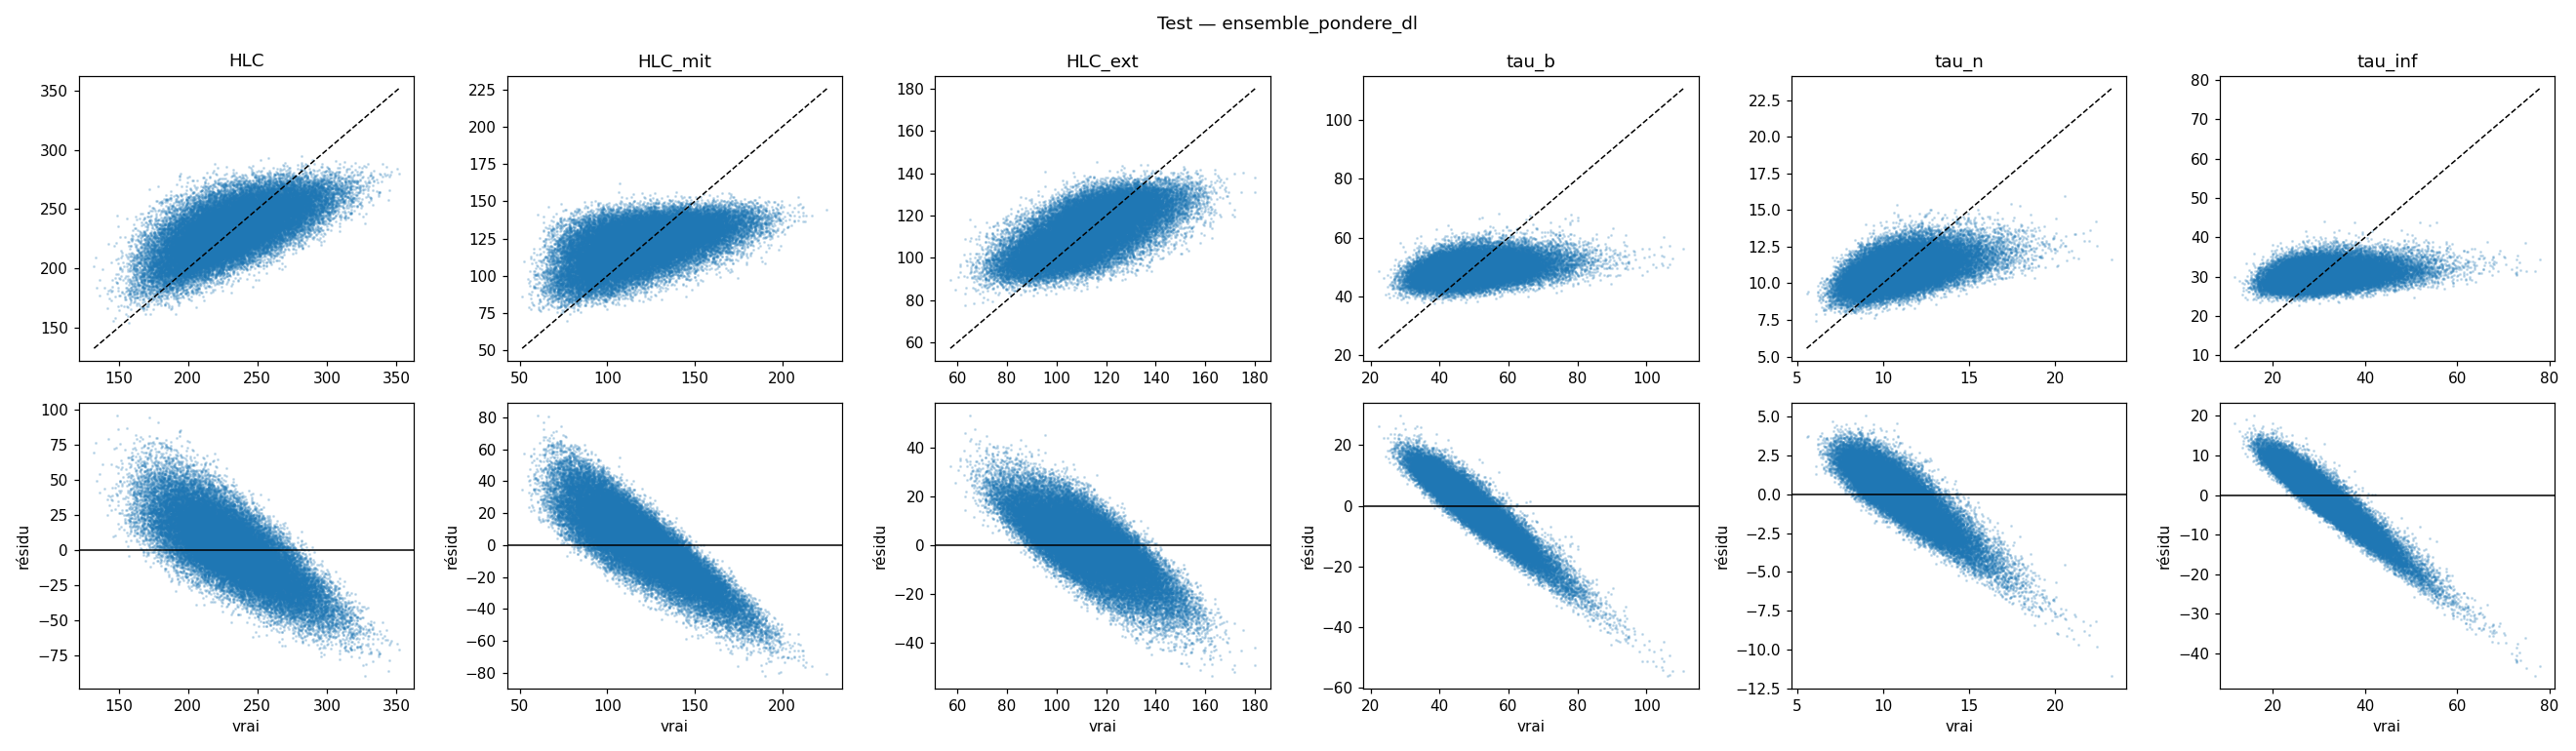


=== R² par nombre de fronts ===


,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf,effectif
≤1,0.471,0.295,0.514,0.145,0.288,0.111,8113.0
2-4,0.432,0.278,0.454,0.115,0.237,0.083,24195.0
≥5,0.406,0.265,0.300,0.065,0.205,0.048,9434.0



=== R² par p on ===


,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf,effectif
"(0.19, 0.4]",0.424,0.268,0.447,0.146,0.235,0.104,9361.0
"(0.4, 0.6]",0.429,0.279,0.423,0.094,0.228,0.067,13975.0
"(0.6, 0.91]",0.442,0.284,0.426,0.102,0.250,0.079,18406.0



=== R² par premier allumage ===


,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf,effectif
1-3 h,0.451,0.284,0.473,0.115,0.260,0.088,21234.0
<1 h,0.409,0.275,0.345,0.081,0.209,0.058,15751.0
>3 h,0.435,0.268,0.515,0.176,0.245,0.125,4757.0


... (2 outputs left out)


=== R² par énergie injectée ===


,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf,effectif
"(35.933, 54.6]",0.467,0.298,0.453,0.104,0.260,0.079,9915.0
"(30.333, 35.933]",0.442,0.274,0.453,0.100,0.260,0.079,9765.0
"(2.099, 19.717]",0.415,0.263,0.448,0.135,0.228,0.095,10906.0
"(19.717, 30.333]",0.415,0.281,0.372,0.096,0.213,0.069,11156.0



=== Robustesse au bruit ===


,,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf,R² moyen
ensemble_pondere_dl,0.00,0.4336,0.2786,0.4300,0.1090,0.2393,0.0806,0.2619
optuna_best,0.00,0.4275,0.2765,0.4191,0.1026,0.2309,0.0751,0.2553
ensemble_pondere_dl,0.05,0.1581,0.2115,-0.3005,-0.1500,-0.0479,-0.1101,-0.0398
optuna_best,0.05,-0.0495,0.1402,-0.6203,-0.3556,-0.3310,-0.2945,-0.2518
ensemble_pondere_dl,0.10,0.0745,0.2003,-0.4195,-0.1804,-0.1286,-0.1296,-0.0972
optuna_best,0.10,-0.2553,0.0902,-0.8621,-0.4755,-0.5737,-0.4009,-0.4129
ensemble_pondere_dl,0.25,-0.0628,0.1693,-0.5758,-0.2358,-0.2109,-0.1633,-0.1799
optuna_best,0.25,-0.5171,0.0146,-1.1413,-0.5922,-0.7552,-0.4964,-0.5813
ensemble_pondere_dl,0.50,-0.2231,0.1103,-0.6889,-0.2986,-0.2079,-0.1856,-0.2490
optuna_best,0.50,-0.7379,-0.0653,-1.3301,-0.6400,-0.7181,-0.5035,-0.6658


In [5]:
if RES:
    if (RES / "residus_dl.png").exists():
        display(Image(filename=str(RES / "residus_dl.png")))
    for f in sorted(RES.glob("segment_*.csv")):
        print("\n===", f.stem.replace("segment_", "R² par ").replace("_", " "), "===")
        show_csv(RES, f.name, index_col=0)
    print("\n=== Robustesse au bruit ===")
    show_csv(RES, "robustesse_bruit_dl.csv", index_col=[0, 1])

## 16. Conclusions de la phase A2

Résultats sur le **test** (mêmes simulations que dans le modèle final, voir
`modelisation.ipynb`, section 5.2) :

| Modèle | R² HLC | R² moyen |
|---|---|---|
| Moyenne | 0.000 | −0.005 |
| Ridge | 0.313 | 0.127 |
| LightGBM | 0.349 | 0.153 |
| Meilleur modèle Optuna (CNN-GRU) | 0.428 | 0.255 |
| **Ensemble pondéré PyTorch** | **0.434** | **0.262** |

R² HLC sur la **validation** des principales architectures, recalculé sur les mêmes simulations dans
`modelisation.ipynb`, section 5.1 :

| CNN-GRU | TCN | CNN-GRU large | Hybride CNN-GRU | Hybride TCN | CNN |
|---|---|---|---|---|---|
| 0.438 | 0.432 | 0.424 | 0.429 | 0.426 | 0.417 |

**Ce qu'on en retient**
1. **Lire les séries bat les variables résumées** : +0.08 de R² HLC par rapport à LightGBM, et un écart
   encore plus net sur HLC_ext.
2. **Le CNN-GRU est la meilleure architecture.** La récurrence aide : le CNN seul est le moins bon. La
   capacité n'est pas limitante : le modèle large ne fait pas mieux.
3. **Ajouter les descripteurs physiques n'aide pas** : les hybrides sont légèrement moins bons. Le réseau
   extrait déjà de la série l'information des descripteurs.
4. **Optuna apporte un gain modeste**, et la variabilité entre graines est faible (écart-type du R²
   moyen ≈ 0,001). Les différences entre architectures sont donc réelles, mais toutes plafonnent autour de
   0,43-0,44 en HLC : c'est le **plafond d'information** identifié dans l'EDA.
5. **Les modèles entraînés sur données propres sont fragiles au bruit capteur**, d'où le modèle robuste
   de la phase finale.

**Décisions transmises aux phases suivantes** : architecture CNN-GRU, configuration Optuna,
paramétrisation A, découpage `splits.npz`.